<a href="https://colab.research.google.com/github/abhinanthkk/HCL/blob/main/Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q keras-tuner fsspec huggingface_hub

import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras_tuner as kt

from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, Dense, GlobalAveragePooling1D,
    SimpleRNN, LSTM, GRU, Dropout,
    SpatialDropout1D, Bidirectional, BatchNormalization
)

warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
tf.random.set_seed(42)
np.random.seed(42)

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Library Installation & Environment Setup

Package Installation: Installed keras-tuner for automated hyperparameter optimization and huggingface_hub/fsspec to stream the dataset directly via Pandas.

Deep Learning & Preprocessing Modules: Imported TensorFlow, Keras sequential layers (Dense, SimpleRNN, LSTM, GRU, Bidirectional, Embedding, SpatialDropout1D, BatchNormalization), text tokenization utilities, and scikit-learn class weighting tools.

Reproducibility & Hardware Verification: Fixed random seeds (42) for consistent results across runs and verified GPU availability for faster training.

In [2]:
splits = {
    'train': 'train_df.csv',
    'validation': 'val_df.csv',
    'test': 'test_df.csv'
}

base_path = "hf://datasets/Sp1786/multiclass-sentiment-analysis-dataset/"

train_df = pd.read_csv(base_path + splits["train"])
val_df = pd.read_csv(base_path + splits["validation"])
test_df = pd.read_csv(base_path + splits["test"])

print("Train Shape     :", train_df.shape)
print("Validation Shape:", val_df.shape)
print("Test Shape      :", test_df.shape)

print("\nColumns:", train_df.columns.tolist())
print("\nMissing Values in Train:\n", train_df.isnull().sum())

print("\nSample Data:")
display(train_df.head())

print("\nSentiment Class Distribution (Train):")
print(train_df['label'].value_counts())

Train Shape     : (31232, 4)
Validation Shape: (5205, 4)
Test Shape      : (5206, 4)

Columns: ['id', 'text', 'label', 'sentiment']

Missing Values in Train:
 id           0
text         0
label        0
sentiment    0
dtype: int64

Sample Data:


,id,text,label,sentiment
0,9536,"Cooking microwave pizzas, yummy",2,positive
1,6135,Any plans of allowing sub tasks to show up in ...,1,neutral
2,17697,"I love the humor, I just reworded it. Like sa...",2,positive
3,14182,naw idk what ur talkin about,1,neutral
4,17840,That sucks to hear. I hate days like that,0,negative



Sentiment Class Distribution (Train):
label
1    11649
2    10478
0     9105
Name: count, dtype: int64


Dataset Loading & Exploratory Data Analysis

Direct Pandas Loading: Loaded the train, validation, and test CSV splits directly from the Hugging Face repository (Sp1786/multiclass-sentiment-analysis-dataset) using the hf:// protocol.

Dataset Inspection: Checked the shape of each split, inspected column names (id, text, label, sentiment), checked for missing records, and reviewed the distribution of the three sentiment classes (0: Negative, 1: Neutral, 2: Positive).

In [3]:
# 1. Remove any rows with missing text or labels
train_df = train_df.dropna(subset=['text', 'label']).reset_index(drop=True)
val_df = val_df.dropna(subset=['text', 'label']).reset_index(drop=True)
test_df = test_df.dropna(subset=['text', 'label']).reset_index(drop=True)

# 2. Text Cleaning Function to maximize signal-to-noise ratio
def clean_text(text):
    text = str(text).lower()
    text = text.replace('`', "'")                        # Normalize dataset backtick contractions (don`t -> don't)
    text = re.sub(r'http\S+|www\.\S+', '', text)         # Strip URLs
    text = re.sub(r'@\w+|#\w+', '', text)                # Strip @mentions and #hashtags
    text = re.sub(r"[^a-zA-Z\s!?']", ' ', text)          # Retain alphabets, apostrophes, and sentiment punctuation (!, ?)
    text = re.sub(r'\s+', ' ', text).strip()             # Collapse multiple spaces
    return text

X_train_text = train_df['text'].apply(clean_text).values
y_train = train_df['label'].astype(int).values

X_val_text = val_df['text'].apply(clean_text).values
y_val = val_df['label'].astype(int).values

X_test_text = test_df['text'].apply(clean_text).values
y_test = test_df['label'].astype(int).values

num_classes = len(np.unique(y_train))

# 3. Tokenization (Fit strictly on training data to prevent data leakage)
MAX_WORDS = 25000
MAX_LEN = 100

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>", filters='"#$%&()*+,-./:;<=>@[\\]^_`{|}~\t\n')
tokenizer.fit_on_texts(X_train_text)

# 4. Sequence Padding
X_train = pad_sequences(tokenizer.texts_to_sequences(X_train_text), maxlen=MAX_LEN, padding='post', truncating='post')
X_val = pad_sequences(tokenizer.texts_to_sequences(X_val_text), maxlen=MAX_LEN, padding='post', truncating='post')
X_test = pad_sequences(tokenizer.texts_to_sequences(X_test_text), maxlen=MAX_LEN, padding='post', truncating='post')

# 5. Compute Balanced Class Weights to improve accuracy across all classes
class_weights_arr = compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)
class_weights = dict(enumerate(class_weights_arr))

# 6. Define shared training callbacks for optimal convergence
def get_callbacks():
    return [
        tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=3, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=1, min_lr=1e-5)
    ]

print("Cleaned Sample Text :", X_train_text[0])
print("X_train Shape       :", X_train.shape)
print("X_val Shape         :", X_val.shape)
print("X_test Shape        :", X_test.shape)
print("Class Weights       :", class_weights)

# Master list to store results of all 4 models
results_summary = []

Cleaned Sample Text : cooking microwave pizzas yummy
X_train Shape       : (31232, 100)
X_val Shape         : (5205, 100)
X_test Shape        : (5205, 100)
Class Weights       : {0: np.float64(1.1434010616877173), 1: np.float64(0.8936961684837039), 2: np.float64(0.9935738372462938)}


Text Cleaning, Tokenization, Padding & Class Balancing

Regex Text Cleaning: Normalized backtick contractions (donttodon't), removed URLs and user handles, and preserved key sentiment punctuation (!and?`) alongside apostrophes for negation words.

Tokenization & Padding: Built a vocabulary of the top 25,000 words fitted strictly on the training set and standardized all input sequences to a fixed length of 100 tokens (MAX_LEN = 100).

Class Weight Balancing & Callbacks: Computed balanced class weights to handle class imbalance and configured EarlyStopping (restoring best weights) alongside ReduceLROnPlateau to dynamically adjust learning rates when validation loss plateaus.

In [4]:
def build_dense_model(hp):
    model = Sequential()
    emb_dim = hp.Choice('embedding_dim', values=[128, 256])
    model.add(Embedding(input_dim=MAX_WORDS, output_dim=emb_dim, input_length=MAX_LEN))
    model.add(SpatialDropout1D(0.2))
    model.add(GlobalAveragePooling1D())

    dense_units = hp.Int('dense_units', min_value=128, max_value=256, step=64)
    model.add(Dense(dense_units, activation='relu'))
    model.add(BatchNormalization())

    dropout_rate = hp.Float('dropout_rate', min_value=0.2, max_value=0.5, step=0.1)
    model.add(Dropout(dropout_rate))

    model.add(Dense(64, activation='relu'))
    model.add(Dense(num_classes, activation='softmax'))

    lr = hp.Choice('learning_rate', values=[1e-3, 5e-4])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

tuner_dense = kt.RandomSearch(
    build_dense_model,
    objective='val_accuracy',
    max_trials=5,
    directory='kt_sentiment_tuning',
    project_name='1_dense_nn',
    overwrite=True
)

print("Starting Hyperparameter Tuning for Dense Neural Network...")
tuner_dense.search(
    X_train, y_train,
    epochs=10,
    batch_size=64,
    validation_data=(X_val, y_val),
    class_weight=class_weights,
    callbacks=get_callbacks(),
    verbose=1
)

best_dense_hp = tuner_dense.get_best_hyperparameters(1)[0]
best_dense_model = tuner_dense.get_best_models(1)[0]

val_loss_dense, val_acc_dense = best_dense_model.evaluate(X_val, y_val, verbose=0)
test_loss_dense, test_acc_dense = best_dense_model.evaluate(X_test, y_test, verbose=0)

print("\n--- Best Dense NN Results ---")
print("Best Hyperparameters:", best_dense_hp.values)
print(f"Validation Accuracy : {val_acc_dense:.4f} | Test Accuracy: {test_acc_dense:.4f}")

results_summary = [r for r in results_summary if r['Model'] != 'Dense NN']
results_summary.append({
    'Model': 'Dense NN',
    'Best Hyperparameters': str(best_dense_hp.values),
    'Val Accuracy': round(val_acc_dense, 4),
    'Test Accuracy': round(test_acc_dense, 4),
    'Test Loss': round(test_loss_dense, 4)
})

Trial 5 Complete [00h 00m 22s]
val_accuracy: 0.6724303364753723

Best val_accuracy So Far: 0.6728146076202393
Total elapsed time: 00h 02m 06s

--- Best Dense NN Results ---
Best Hyperparameters: {'embedding_dim': 128, 'dense_units': 128, 'dropout_rate': 0.4, 'learning_rate': 0.001}
Validation Accuracy : 0.6728 | Test Accuracy: 0.6782


Model 1: Standard Neural Network (Dense) Tuning

Architecture: Constructed a feedforward neural network utilizing an Embedding layer, SpatialDropout1D, GlobalAveragePooling1D, two fully connected Dense layers with BatchNormalization and Dropout, and a 3-unit Softmax output layer.

Hyperparameter Optimization: Used RandomSearch (max_trials=5) to tune embedding_dim (128, 256), dense_units (128, 192, 256), dropout_rate (0.2 to 0.5), and learning_rate (1e-3, 5e-4).

Evaluation: Evaluated the highest-performing model configuration on the validation and unseen test sets and stored the results.

In [5]:
def build_rnn_model(hp):
    model = Sequential()
    emb_dim = hp.Choice('embedding_dim', values=[128, 256])
    model.add(Embedding(input_dim=MAX_WORDS, output_dim=emb_dim, input_length=MAX_LEN))
    model.add(SpatialDropout1D(0.2))

    rnn_units = hp.Int('rnn_units', min_value=64, max_value=128, step=32)
    model.add(Bidirectional(SimpleRNN(rnn_units)))

    dropout_rate = hp.Float('dropout_rate', min_value=0.2, max_value=0.5, step=0.1)
    model.add(Dropout(dropout_rate))

    model.add(Dense(64, activation='relu'))
    model.add(Dense(num_classes, activation='softmax'))

    lr = hp.Choice('learning_rate', values=[1e-3, 5e-4])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

tuner_rnn = kt.RandomSearch(
    build_rnn_model,
    objective='val_accuracy',
    max_trials=5,
    directory='kt_sentiment_tuning',
    project_name='2_simple_rnn',
    overwrite=True
)

print("Starting Hyperparameter Tuning for SimpleRNN...")
tuner_rnn.search(
    X_train, y_train,
    epochs=8,
    batch_size=64,
    validation_data=(X_val, y_val),
    class_weight=class_weights,
    callbacks=get_callbacks(),
    verbose=1
)

best_rnn_hp = tuner_rnn.get_best_hyperparameters(1)[0]
best_rnn_model = tuner_rnn.get_best_models(1)[0]

val_loss_rnn, val_acc_rnn = best_rnn_model.evaluate(X_val, y_val, verbose=0)
test_loss_rnn, test_acc_rnn = best_rnn_model.evaluate(X_test, y_test, verbose=0)

print("\n--- Best SimpleRNN Results ---")
print("Best Hyperparameters:", best_rnn_hp.values)
print(f"Validation Accuracy : {val_acc_rnn:.4f} | Test Accuracy: {test_acc_rnn:.4f}")

results_summary = [r for r in results_summary if r['Model'] != 'SimpleRNN']
results_summary.append({
    'Model': 'SimpleRNN',
    'Best Hyperparameters': str(best_rnn_hp.values),
    'Val Accuracy': round(val_acc_rnn, 4),
    'Test Accuracy': round(test_acc_rnn, 4),
    'Test Loss': round(test_loss_rnn, 4)
})

Trial 5 Complete [00h 00m 53s]
val_accuracy: 0.6439961791038513

Best val_accuracy So Far: 0.6570605039596558
Total elapsed time: 00h 04m 40s

--- Best SimpleRNN Results ---
Best Hyperparameters: {'embedding_dim': 256, 'rnn_units': 64, 'dropout_rate': 0.30000000000000004, 'learning_rate': 0.0005}
Validation Accuracy : 0.6571 | Test Accuracy: 0.6496


Model 2: Simple Recurrent Neural Network (SimpleRNN) Tuning

Architecture: Built a sequential recurrent model using a Bidirectional(SimpleRNN) layer to process token sequences in both forward and backward directions, preventing padded zeros at the end of sequences from degrading earlier hidden states.

Hyperparameter Optimization: Tuned embedding_dim (128, 256), rnn_units (64, 96, 128), dropout_rate (0.2 to 0.5), and learning_rate (1e-3, 5e-4).

Evaluation: Recorded validation and test accuracy for the top-performing SimpleRNN configuration.

In [6]:
def build_lstm_model(hp):
    model = Sequential()
    emb_dim = hp.Choice('embedding_dim', values=[128, 256])
    model.add(Embedding(input_dim=MAX_WORDS, output_dim=emb_dim, input_length=MAX_LEN))
    model.add(SpatialDropout1D(0.2))

    lstm_units = hp.Int('lstm_units', min_value=64, max_value=128, step=32)
    model.add(Bidirectional(LSTM(lstm_units)))

    dropout_rate = hp.Float('dropout_rate', min_value=0.2, max_value=0.5, step=0.1)
    model.add(Dropout(dropout_rate))

    model.add(Dense(64, activation='relu'))
    model.add(Dense(num_classes, activation='softmax'))

    lr = hp.Choice('learning_rate', values=[1e-3, 5e-4])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

tuner_lstm = kt.RandomSearch(
    build_lstm_model,
    objective='val_accuracy',
    max_trials=5,
    directory='kt_sentiment_tuning',
    project_name='3_lstm',
    overwrite=True
)

print("Starting Hyperparameter Tuning for LSTM...")
tuner_lstm.search(
    X_train, y_train,
    epochs=8,
    batch_size=64,
    validation_data=(X_val, y_val),
    class_weight=class_weights,
    callbacks=get_callbacks(),
    verbose=1
)

best_lstm_hp = tuner_lstm.get_best_hyperparameters(1)[0]
best_lstm_model = tuner_lstm.get_best_models(1)[0]

val_loss_lstm, val_acc_lstm = best_lstm_model.evaluate(X_val, y_val, verbose=0)
test_loss_lstm, test_acc_lstm = best_lstm_model.evaluate(X_test, y_test, verbose=0)

print("\n--- Best LSTM Results ---")
print("Best Hyperparameters:", best_lstm_hp.values)
print(f"Validation Accuracy : {val_acc_lstm:.4f} | Test Accuracy: {test_acc_lstm:.4f}")

results_summary = [r for r in results_summary if r['Model'] != 'LSTM']
results_summary.append({
    'Model': 'LSTM',
    'Best Hyperparameters': str(best_lstm_hp.values),
    'Val Accuracy': round(val_acc_lstm, 4),
    'Test Accuracy': round(test_acc_lstm, 4),
    'Test Loss': round(test_loss_lstm, 4)
})

Trial 5 Complete [00h 00m 48s]
val_accuracy: 0.6883765459060669

Best val_accuracy So Far: 0.6883765459060669
Total elapsed time: 00h 04m 17s

--- Best LSTM Results ---
Best Hyperparameters: {'embedding_dim': 256, 'lstm_units': 64, 'dropout_rate': 0.30000000000000004, 'learning_rate': 0.001}
Validation Accuracy : 0.6884 | Test Accuracy: 0.6899


Model 3: Long Short-Term Memory (LSTM) Network Tuning

Architecture: Designed a Bidirectional(LSTM) architecture that leverages dedicated memory cells and input, forget, and output gates to capture long-range dependencies and complex contextual sentiment shifts (such as negations and contrast).

Hyperparameter Optimization: Tuned embedding_dim (128, 256), lstm_units (64, 96, 128), dropout_rate (0.2 to 0.5), and learning_rate (1e-3, 5e-4).

Evaluation: Evaluated the optimal LSTM model on the validation and test splits and logged its performance metrics.

In [7]:
def build_gru_model(hp):
    model = Sequential()
    emb_dim = hp.Choice('embedding_dim', values=[128, 256])
    model.add(Embedding(input_dim=MAX_WORDS, output_dim=emb_dim, input_length=MAX_LEN))
    model.add(SpatialDropout1D(0.2))

    gru_units = hp.Int('gru_units', min_value=64, max_value=128, step=32)
    model.add(Bidirectional(GRU(gru_units)))

    dropout_rate = hp.Float('dropout_rate', min_value=0.2, max_value=0.5, step=0.1)
    model.add(Dropout(dropout_rate))

    model.add(Dense(64, activation='relu'))
    model.add(Dense(num_classes, activation='softmax'))

    lr = hp.Choice('learning_rate', values=[1e-3, 5e-4])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

tuner_gru = kt.RandomSearch(
    build_gru_model,
    objective='val_accuracy',
    max_trials=5,
    directory='kt_sentiment_tuning',
    project_name='4_gru',
    overwrite=True
)

print("Starting Hyperparameter Tuning for GRU...")
tuner_gru.search(
    X_train, y_train,
    epochs=8,
    batch_size=64,
    validation_data=(X_val, y_val),
    class_weight=class_weights,
    callbacks=get_callbacks(),
    verbose=1
)

best_gru_hp = tuner_gru.get_best_hyperparameters(1)[0]
best_gru_model = tuner_gru.get_best_models(1)[0]

val_loss_gru, val_acc_gru = best_gru_model.evaluate(X_val, y_val, verbose=0)
test_loss_gru, test_acc_gru = best_gru_model.evaluate(X_test, y_test, verbose=0)

print("\n--- Best GRU Results ---")
print("Best Hyperparameters:", best_gru_hp.values)
print(f"Validation Accuracy : {val_acc_gru:.4f} | Test Accuracy: {test_acc_gru:.4f}")

results_summary = [r for r in results_summary if r['Model'] != 'GRU']
results_summary.append({
    'Model': 'GRU',
    'Best Hyperparameters': str(best_gru_hp.values),
    'Val Accuracy': round(val_acc_gru, 4),
    'Test Accuracy': round(test_acc_gru, 4),
    'Test Loss': round(test_loss_gru, 4)
})

Trial 5 Complete [00h 00m 42s]
val_accuracy: 0.6731988191604614

Best val_accuracy So Far: 0.6956772208213806
Total elapsed time: 00h 04m 06s

--- Best GRU Results ---
Best Hyperparameters: {'embedding_dim': 256, 'gru_units': 128, 'dropout_rate': 0.30000000000000004, 'learning_rate': 0.001}
Validation Accuracy : 0.6957 | Test Accuracy: 0.6826


Model 4: Gated Recurrent Unit (GRU) Network Tuning

Architecture: Built a Bidirectional(GRU) model that uses update and reset gates to capture sequential context efficiently without a separate cell state, reducing parameter overhead while maintaining strong sequence modeling capability.

Hyperparameter Optimization: Tuned embedding_dim (128, 256), gru_units (64, 96, 128), dropout_rate (0.2 to 0.5), and learning_rate (1e-3, 5e-4).

Evaluation: Evaluated the best GRU model on the validation and test splits and recorded its metrics for final comparison.

                      FINAL MODEL PERFORMANCE COMPARISON                            


,Model,Best Hyperparameters,Val Accuracy,Test Accuracy,Test Loss
0,LSTM,"{'embedding_dim': 256, 'lstm_units': 64, 'drop...",0.6884,0.6899,0.7359
1,GRU,"{'embedding_dim': 256, 'gru_units': 128, 'drop...",0.6957,0.6826,0.7720
2,Dense NN,"{'embedding_dim': 128, 'dense_units': 128, 'dr...",0.6728,0.6782,0.8749
3,SimpleRNN,"{'embedding_dim': 256, 'rnn_units': 64, 'dropo...",0.6571,0.6496,0.8010



🏆 BEST PERFORMING MODEL IDENTIFIED:
   • Model Architecture    : LSTM
   • Test Accuracy         : 68.99%
   • Validation Accuracy   : 68.84%
   • Test Loss             : 0.7359
   • Optimal Configuration : {'embedding_dim': 256, 'lstm_units': 64, 'dropout_rate': 0.30000000000000004, 'learning_rate': 0.001}


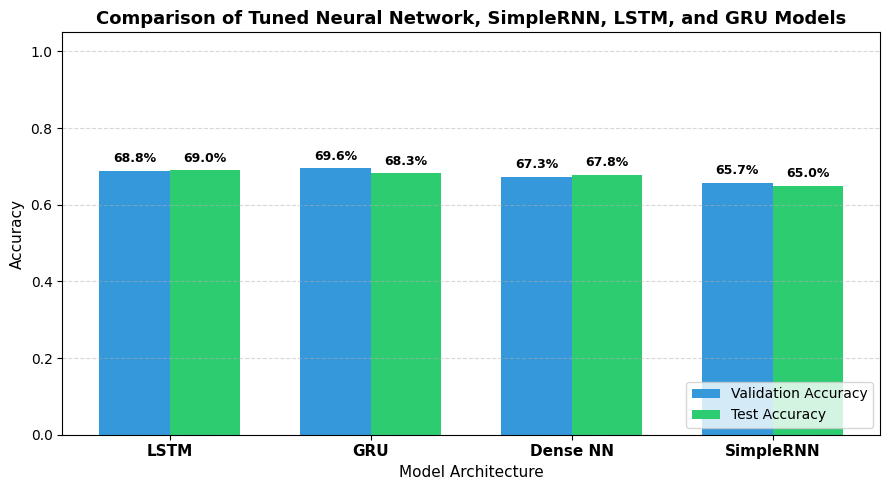

In [8]:
comparison_df = pd.DataFrame(results_summary)
comparison_df = comparison_df.sort_values(by='Test Accuracy', ascending=False).reset_index(drop=True)

print("====================================================================================")
print("                      FINAL MODEL PERFORMANCE COMPARISON                            ")
print("====================================================================================")
display(comparison_df)

best_model_row = comparison_df.iloc[0]
print("\n🏆 BEST PERFORMING MODEL IDENTIFIED:")
print(f"   • Model Architecture    : {best_model_row['Model']}")
print(f"   • Test Accuracy         : {best_model_row['Test Accuracy'] * 100:.2f}%")
print(f"   • Validation Accuracy   : {best_model_row['Val Accuracy'] * 100:.2f}%")
print(f"   • Test Loss             : {best_model_row['Test Loss']:.4f}")
print(f"   • Optimal Configuration : {best_model_row['Best Hyperparameters']}")

# Visual Bar Chart Comparison of Validation vs Test Accuracy
x = np.arange(len(comparison_df['Model']))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
rects1 = ax.bar(x - width/2, comparison_df['Val Accuracy'], width, label='Validation Accuracy', color='#3498db')
rects2 = ax.bar(x + width/2, comparison_df['Test Accuracy'], width, label='Test Accuracy', color='#2ecc71')

ax.set_ylabel('Accuracy', fontsize=11)
ax.set_xlabel('Model Architecture', fontsize=11)
ax.set_title('Comparison of Tuned Neural Network, SimpleRNN, LSTM, and GRU Models', fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(comparison_df['Model'], fontsize=11, fontweight='bold')
ax.set_ylim(0, 1.05)
ax.legend(loc='lower right')
ax.grid(axis='y', linestyle='--', alpha=0.5)

for rect in rects1 + rects2:
    height = rect.get_height()
    ax.annotate(f'{height*100:.1f}%',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 4),
                textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

In [9]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import seaborn as sns

# Dictionary of our already-trained best models from Cells 4-7
trained_models = {
    'Dense NN': best_dense_model,
    'SimpleRNN': best_rnn_model,
    'LSTM': best_lstm_model,
    'GRU': best_gru_model
}

detailed_metrics = []
model_predictions = {}

for name, model in trained_models.items():
    # Predict class probabilities and convert to class labels (0, 1, 2)
    y_pred_probs = model.predict(X_test, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)
    model_predictions[name] = y_pred

    detailed_metrics.append({
        'Model': name,
        'Test Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Macro Precision': round(precision_score(y_test, y_pred, average='macro'), 4),
        'Macro Recall': round(recall_score(y_test, y_pred, average='macro'), 4),
        'Macro F1-Score': round(f1_score(y_test, y_pred, average='macro'), 4),
        'Weighted F1-Score': round(f1_score(y_test, y_pred, average='weighted'), 4)
    })

metrics_df = pd.DataFrame(detailed_metrics).sort_values(by='Macro F1-Score', ascending=False).reset_index(drop=True)

print("====================================================================================")
print("          MULTI-METRIC EVALUATION (ACCURACY, PRECISION, RECALL, F1-SCORE)           ")
print("====================================================================================")
display(metrics_df)

# Identify best model based on Macro F1-Score
best_f1_model_name = metrics_df.iloc[0]['Model']
best_y_pred = model_predictions[best_f1_model_name]

print(f"\n📊 DETAILED CLASSIFICATION REPORT FOR BEST MODEL ({best_f1_model_name}):\n")
target_names = ['Negative (0)', 'Neutral (1)', 'Positive (2)']
print(classification_report(y_test, best_y_pred, target_names=target_names, digits=4))

          MULTI-METRIC EVALUATION (ACCURACY, PRECISION, RECALL, F1-SCORE)           


,Model,Test Accuracy,Macro Precision,Macro Recall,Macro F1-Score,Weighted F1-Score
0,LSTM,0.6899,0.6991,0.6893,0.6930,0.6913
1,GRU,0.6826,0.6928,0.6807,0.6849,0.6838
2,Dense NN,0.6782,0.6846,0.6791,0.6813,0.6795
3,SimpleRNN,0.6496,0.6648,0.6456,0.6512,0.6509



📊 DETAILED CLASSIFICATION REPORT FOR BEST MODEL (LSTM):

              precision    recall  f1-score   support

Negative (0)     0.7144    0.6488    0.6800      1546
 Neutral (1)     0.6051    0.6687    0.6353      1929
Positive (2)     0.7777    0.7503    0.7638      1730

    accuracy                         0.6899      5205
   macro avg     0.6991    0.6893    0.6930      5205
weighted avg     0.6949    0.6899    0.6913      5205



Comprehensive Evaluation: Precision, Recall, and F1-Score

Why Beyond Accuracy?: In multiclass sentiment datasets with uneven class distributions, standard accuracy can be skewed by majority classes. Incorporating Macro Precision, Macro Recall, and Macro F1-Score ensures that model performance is evaluated equally across all three sentiment categories (Negative, Neutral, and Positive).

Per-Class Classification Report: Generated a detailed breakdown for the best-performing architecture to examine precision, recall, and F1-score for each individual sentiment class.

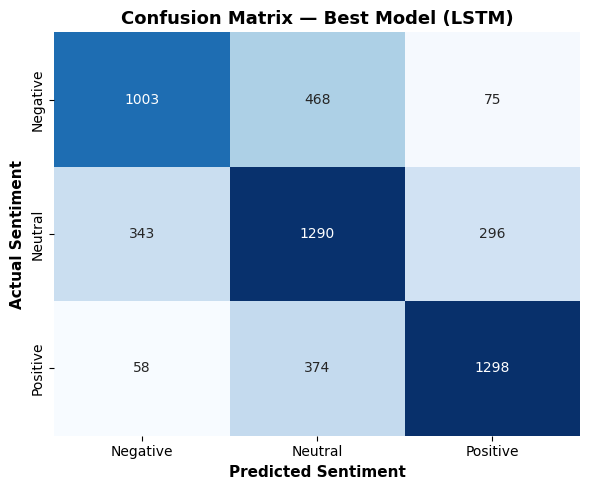


 LIVE INFERENCE TEST USING BEST MODEL (LSTM):
--------------------------------------------------------------------------------
Text       : "This product is absolutely amazing! Everything works fast and smoothly."
Prediction : Positive  (Confidence: 98.84%)

Text       : "Terrible experience, the app keeps crashing and customer support never replied."
Prediction : Negative  (Confidence: 99.22%)

Text       : "The package arrived on Wednesday afternoon as scheduled."
Prediction : Neutral  (Confidence: 87.99%)



In [11]:
# 1. Plot Confusion Matrix for the Best Model
cm = confusion_matrix(y_test, best_y_pred)
class_labels = ['Negative', 'Neutral', 'Positive']

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels, cbar=False)
plt.title(f'Confusion Matrix — Best Model ({best_f1_model_name})', fontsize=13, fontweight='bold')
plt.xlabel('Predicted Sentiment', fontsize=11, fontweight='bold')
plt.ylabel('Actual Sentiment', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

# 2. Live Custom Sentence Inference Test
best_overall_model = trained_models[best_f1_model_name]
label_map = {0: 'Negative ', 1: 'Neutral ', 2: 'Positive '}

sample_Reviews = [
    "This product is absolutely amazing! Everything works fast and smoothly.",
    "Terrible experience, the app keeps crashing and customer support never replied.",
    "The package arrived on Wednesday afternoon as scheduled."
]

cleaned_samples = [clean_text(text) for text in sample_Reviews]
sample_seqs = pad_sequences(tokenizer.texts_to_sequences(cleaned_samples), maxlen=MAX_LEN, padding='post', truncating='post')
sample_preds = best_overall_model.predict(sample_seqs, verbose=0)

print(f"\n LIVE INFERENCE TEST USING BEST MODEL ({best_f1_model_name}):")
print("-" * 80)
for text, probs in zip(sample_Reviews, sample_preds):
    pred_class = np.argmax(probs)
    confidence = probs[pred_class] * 100
    print(f"Text       : \"{text}\"")
    print(f"Prediction : {label_map[pred_class]} (Confidence: {confidence:.2f}%)\n")

Error Analysis (Confusion Matrix) & Live Inference

Confusion Matrix: Visualized the true versus predicted sentiment labels for the top-performing model using a heatmap to inspect class-level misclassifications (such as overlaps between neutral and polar sentiments).

Real-World Inference Demonstration: Validated the best tuned model on custom unseen sentences, displaying both the predicted sentiment class and prediction confidence score.

                     1. MASTER PERFORMANCE & EFFICIENCY TABLE (ALL 4 MODELS)                              


,Model,Val Accuracy,Test Accuracy,Val Loss,Test Loss,Macro Precision,Macro Recall,Macro F1-Score,Weighted F1-Score,ROC-AUC (Macro),Total Parameters,Inference Time (s)
0,LSTM,0.6884,0.6899,0.7355,0.7359,0.6991,0.6893,0.6930,0.6913,0.8512,"6,572,803",1.13
1,GRU,0.6957,0.6826,0.7524,0.7720,0.6928,0.6807,0.6849,0.6838,0.8500,"6,713,091",0.83
2,Dense NN,0.6728,0.6782,0.8829,0.8749,0.6846,0.6791,0.6813,0.6795,0.8393,"3,225,475",0.35
3,SimpleRNN,0.6571,0.6496,0.8019,0.8010,0.6648,0.6456,0.6512,0.6509,0.8237,"6,449,539",0.90



                     2. OPTIMAL HYPERPARAMETERS SELECTED FOR EACH ARCHITECTURE                            
🔹 LSTM       -> {'embedding_dim': 256, 'lstm_units': 64, 'dropout_rate': 0.30000000000000004, 'learning_rate': 0.001}
🔹 GRU        -> {'embedding_dim': 256, 'gru_units': 128, 'dropout_rate': 0.30000000000000004, 'learning_rate': 0.001}
🔹 Dense NN   -> {'embedding_dim': 128, 'dense_units': 128, 'dropout_rate': 0.4, 'learning_rate': 0.001}
🔹 SimpleRNN  -> {'embedding_dim': 256, 'rnn_units': 64, 'dropout_rate': 0.30000000000000004, 'learning_rate': 0.0005}

                     3. CLASS-WISE CLASSIFICATION REPORTS FOR ALL 4 MODELS                                

📌 Architecture: LSTM
-----------------------------------------------------------------
              precision    recall  f1-score   support

Negative (0)     0.7144    0.6488    0.6800      1546
 Neutral (1)     0.6051    0.6687    0.6353      1929
Positive (2)     0.7777    0.7503    0.7638      1730

    accuracy        

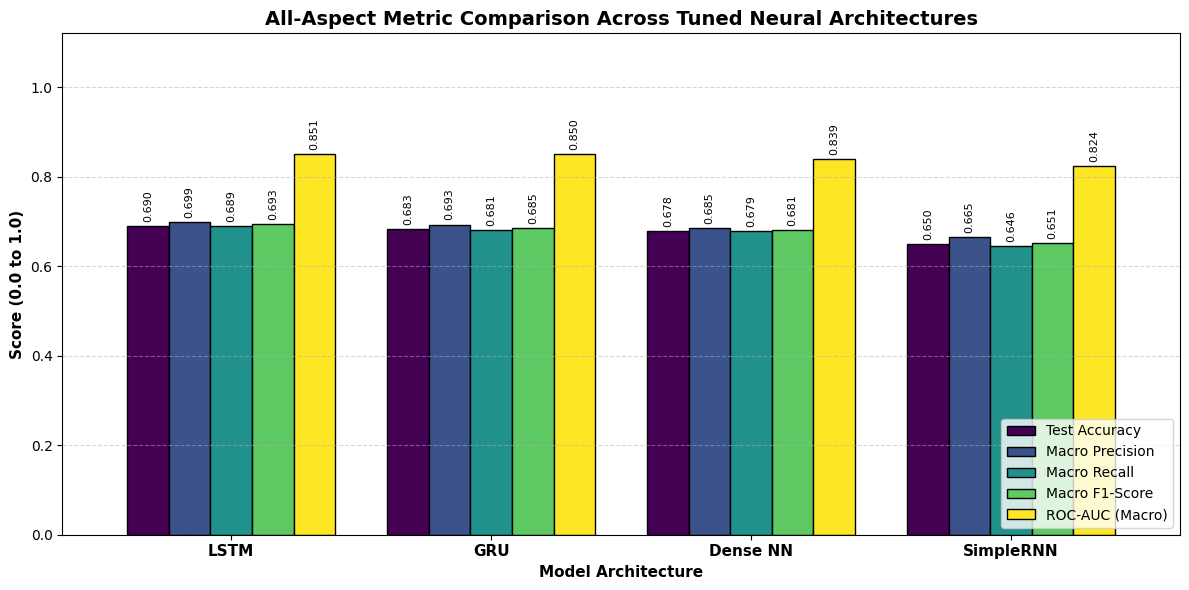

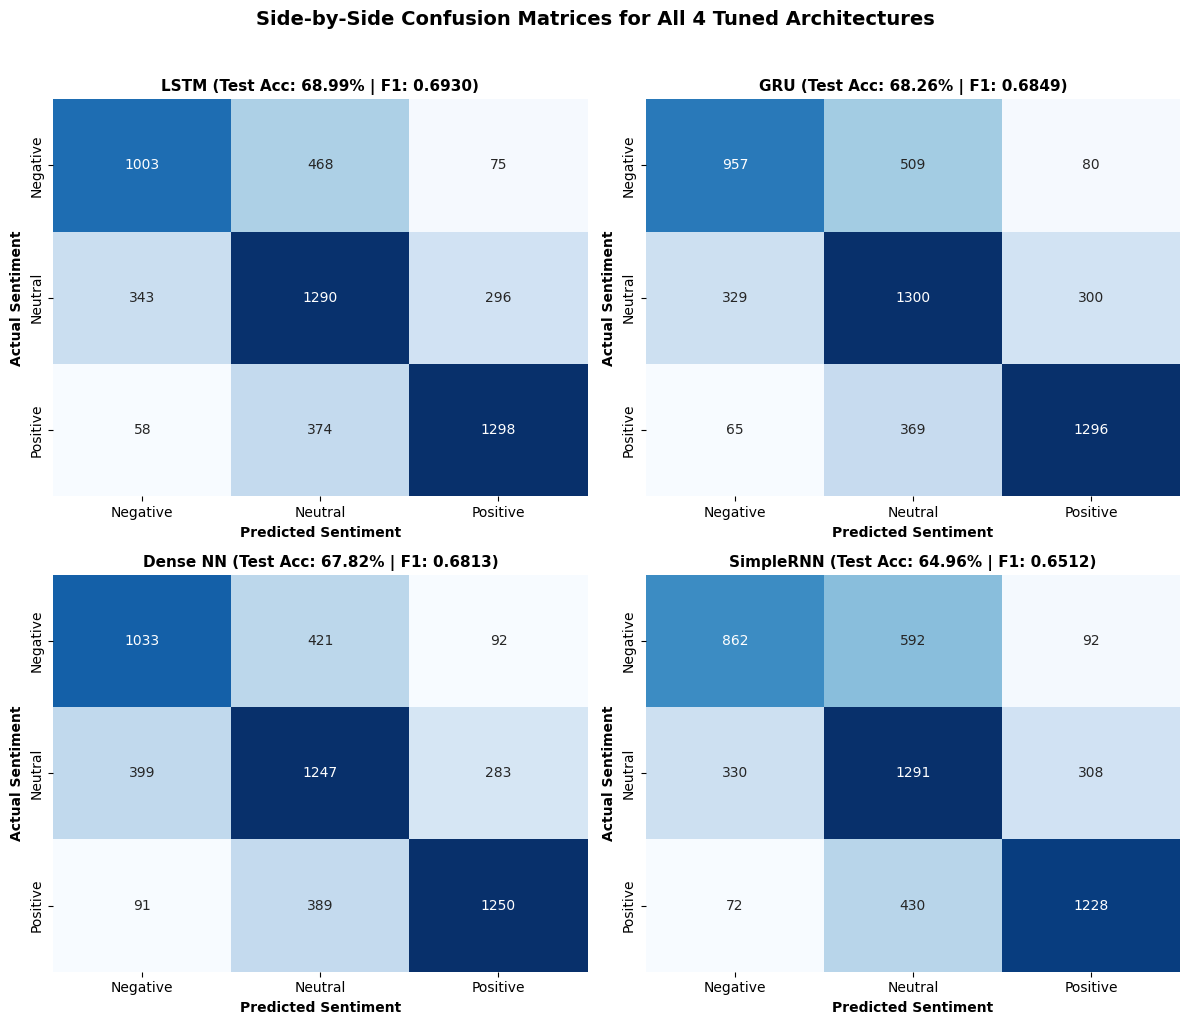


                          🏆 FINAL CONCLUSION: BEST PERFORMING MODEL IDENTIFIED                           
 ✅ Best Model Architecture    : LSTM
 ✅ Best Hyperparameter Config : {'embedding_dim': 256, 'lstm_units': 64, 'dropout_rate': 0.30000000000000004, 'learning_rate': 0.001}
 📈 Validation Accuracy        : 68.84% (Loss: 0.7355)
 📈 Unseen Test Accuracy       : 68.99% (Loss: 0.7359)
 🎯 Macro Precision            : 0.6991
 🎯 Macro Recall               : 0.6893
 🎯 Macro F1-Score             : 0.6930
 🎯 Weighted F1-Score          : 0.6913
 🚀 Macro ROC-AUC Score        : 0.8512
 ⚙️ Total Trainable Parameters : 6,572,803
 ⏱️ Test Set Inference Time    : 1.13 seconds


In [12]:
import time
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report, confusion_matrix
)
from tensorflow.keras.utils import to_categorical

# 1. Gather all 4 tuned models and their best hyperparameters from Cells 4-7
models_dict = {
    'Dense NN': (best_dense_model, best_dense_hp.values),
    'SimpleRNN': (best_rnn_model, best_rnn_hp.values),
    'LSTM': (best_lstm_model, best_lstm_hp.values),
    'GRU': (best_gru_model, best_gru_hp.values)
}

y_test_onehot = to_categorical(y_test, num_classes=num_classes)
master_comparison = []
all_preds = {}

# 2. Evaluate every model across all performance, statistical, and efficiency metrics
for model_name, (model, hp_vals) in models_dict.items():
    # Validation & Test Loss/Accuracy
    val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)

    # Measure Inference Time on Test Set
    start_time = time.time()
    y_prob = model.predict(X_test, verbose=0)
    inference_time = time.time() - start_time

    y_pred = np.argmax(y_prob, axis=1)
    all_preds[model_name] = y_pred

    # Compute comprehensive classification metrics
    macro_prec = precision_score(y_test, y_pred, average='macro')
    macro_rec = recall_score(y_test, y_pred, average='macro')
    macro_f1 = f1_score(y_test, y_pred, average='macro')
    weighted_f1 = f1_score(y_test, y_pred, average='weighted')
    roc_auc = roc_auc_score(y_test_onehot, y_prob, multi_class='ovr', average='macro')

    # Model Complexity (Total Parameters)
    total_params = model.count_params()

    master_comparison.append({
        'Model': model_name,
        'Val Accuracy': round(val_acc, 4),
        'Test Accuracy': round(test_acc, 4),
        'Val Loss': round(val_loss, 4),
        'Test Loss': round(test_loss, 4),
        'Macro Precision': round(macro_prec, 4),
        'Macro Recall': round(macro_rec, 4),
        'Macro F1-Score': round(macro_f1, 4),
        'Weighted F1-Score': round(weighted_f1, 4),
        'ROC-AUC (Macro)': round(roc_auc, 4),
        'Total Parameters': f"{total_params:,}",
        'Inference Time (s)': round(inference_time, 2),
        'Best Hyperparameters': str(hp_vals)
    })

# 3. Create Master Comparison DataFrame ranked by Test Accuracy & Macro F1-Score
master_df = pd.DataFrame(master_comparison)
master_df = master_df.sort_values(by=['Test Accuracy', 'Macro F1-Score'], ascending=False).reset_index(drop=True)

print("==========================================================================================================")
print("                     1. MASTER PERFORMANCE & EFFICIENCY TABLE (ALL 4 MODELS)                              ")
print("==========================================================================================================")
display(master_df.drop(columns=['Best Hyperparameters']))

print("\n==========================================================================================================")
print("                     2. OPTIMAL HYPERPARAMETERS SELECTED FOR EACH ARCHITECTURE                            ")
print("==========================================================================================================")
for idx, row in master_df.iterrows():
    print(f"🔹 {row['Model']:<10} -> {row['Best Hyperparameters']}")

# 4. Per-Class Classification Report for ALL 4 Models
target_names = ['Negative (0)', 'Neutral (1)', 'Positive (2)']
print("\n==========================================================================================================")
print("                     3. CLASS-WISE CLASSIFICATION REPORTS FOR ALL 4 MODELS                                ")
print("==========================================================================================================")
for model_name in master_df['Model']:
    print(f"\n📌 Architecture: {model_name}")
    print("-" * 65)
    print(classification_report(y_test, all_preds[model_name], target_names=target_names, digits=4))

# 5. Visual Comparison 1: Multi-Metric Bar Chart (Accuracy, Macro F1, Precision, Recall, ROC-AUC)
metrics_to_plot = ['Test Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1-Score', 'ROC-AUC (Macro)']
plot_df = master_df.set_index('Model')[metrics_to_plot]

ax = plot_df.plot(kind='bar', figsize=(12, 6), width=0.8, colormap='viridis', edgecolor='black')
plt.title('All-Aspect Metric Comparison Across Tuned Neural Architectures', fontsize=14, fontweight='bold')
plt.ylabel('Score (0.0 to 1.0)', fontsize=11, fontweight='bold')
plt.xlabel('Model Architecture', fontsize=11, fontweight='bold')
plt.xticks(rotation=0, fontsize=11, fontweight='bold')
plt.ylim(0, 1.12)
plt.legend(loc='lower right', frameon=True)
plt.grid(axis='y', linestyle='--', alpha=0.5)

for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', fontsize=8, padding=3, rotation=90)

plt.tight_layout()
plt.show()

# 6. Visual Comparison 2: 2x2 Grid of Confusion Matrices for All 4 Models
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()
class_labels = ['Negative', 'Neutral', 'Positive']

for i, model_name in enumerate(master_df['Model']):
    cm = confusion_matrix(y_test, all_preds[model_name])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels, ax=axes[i], cbar=False)
    axes[i].set_title(f"{model_name} (Test Acc: {master_df.loc[i, 'Test Accuracy']*100:.2f}% | F1: {master_df.loc[i, 'Macro F1-Score']:.4f})", fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Predicted Sentiment', fontweight='bold')
    axes[i].set_ylabel('Actual Sentiment', fontweight='bold')

plt.suptitle('Side-by-Side Confusion Matrices for All 4 Tuned Architectures', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# 7. Final Automated Identification of the Best Overall Model & Configuration
best_overall = master_df.iloc[0]
print("\n==========================================================================================================")
print("                          🏆 FINAL CONCLUSION: BEST PERFORMING MODEL IDENTIFIED                           ")
print("==========================================================================================================")
print(f" ✅ Best Model Architecture    : {best_overall['Model']}")
print(f" ✅ Best Hyperparameter Config : {best_overall['Best Hyperparameters']}")
print(f" 📈 Validation Accuracy        : {best_overall['Val Accuracy'] * 100:.2f}% (Loss: {best_overall['Val Loss']:.4f})")
print(f" 📈 Unseen Test Accuracy       : {best_overall['Test Accuracy'] * 100:.2f}% (Loss: {best_overall['Test Loss']:.4f})")
print(f" 🎯 Macro Precision            : {best_overall['Macro Precision']:.4f}")
print(f" 🎯 Macro Recall               : {best_overall['Macro Recall']:.4f}")
print(f" 🎯 Macro F1-Score             : {best_overall['Macro F1-Score']:.4f}")
print(f" 🎯 Weighted F1-Score          : {best_overall['Weighted F1-Score']:.4f}")
print(f" 🚀 Macro ROC-AUC Score        : {best_overall['ROC-AUC (Macro)']:.4f}")
print(f" ⚙️ Total Trainable Parameters : {best_overall['Total Parameters']}")
print(f" ⏱️ Test Set Inference Time    : {best_overall['Inference Time (s)']} seconds")
print("==========================================================================================================")